# 02 — Tail latency of grinding (RQ2)

1. Per grind config: empirical p50 / p90 / p99 / p99.9 tries vs. the geometric quantiles, and the
   tail-to-mean ratios a wallet must design for.
2. All configs on one scale: the CCDF of tries ÷ E[tries] collapses onto e^(−x) if H1 holds.
3. Per *signature*: d WOTS+C layers + one FORS+C / PORS+FP grind, by resampling the measured samples,
   converted to seconds on each signer class. Grinding only; full signing cost is in notebook 03.

In [1]:
import sys; sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import common as C
OUT = C.out_dir('02_tails')
s = C.summary()
Q = [0.5, 0.9, 0.99, 0.999]

## Per-config quantiles

In [2]:
rows = []
for cid, r in s.iterrows():
    e = r.expected_tries
    row = {'config_id': cid, 'grind': C.KIND_LABEL[r.kind], 'n': int(r.n), 'E': e, 'mean': r.mean_tries}
    for q, col in zip(Q, ['p50', 'p90', 'p99', 'p999']):
        row[col] = r[col]; row[col + '_vs_geo'] = r[col] / r['geo_' + col]
    row['p99_over_mean'] = r.p99 / r.mean_tries
    row['p999_over_mean'] = r.p999 / r.mean_tries
    row['max_over_mean'] = C.tries(cid).max() / r.mean_tries
    rows.append(row)
t = pd.DataFrame(rows).set_index('config_id')
print("geometric: p99/mean = ln(100) = 4.61, p99.9/mean = ln(1000) = 6.91")
print(t[['p99_over_mean', 'p999_over_mean']].describe().loc[['mean', 'min', 'max']].round(3))
print(f"p99.9 vs geometric quantile: {t.p999_vs_geo.min():.3f} .. {t.p999_vs_geo.max():.3f}")
C.to_markdown(t.round(4), OUT / 'quantiles.md'); t.to_csv(OUT / 'quantiles.csv')
t[['grind', 'n', 'E', 'p50_vs_geo', 'p90_vs_geo', 'p99_vs_geo', 'p999_vs_geo', 'p99_over_mean', 'p999_over_mean', 'max_over_mean']]

geometric: p99/mean = ln(100) = 4.61, p99.9/mean = ln(1000) = 6.91
      p99_over_mean  p999_over_mean
mean          4.599           6.904
min           4.557           6.725
max           4.647           7.053
p99.9 vs geometric quantile: 0.978 .. 1.019


,grind,n,E,p50_vs_geo,p90_vs_geo,p99_vs_geo,p999_vs_geo,p99_over_mean,p999_over_mean,max_over_mean
config_id,,,,,,,,,,
wots-w16-S240-z0,WOTS+C,1000000,6.567584e+01,1.000000,0.993377,0.996678,1.000000,4.569547,6.869552,13.510627
wots-w256-S2040-z0,WOTS+C,1000000,7.480070e+02,1.000000,0.997677,0.997676,1.000581,4.595834,6.913151,15.566966
wots-w16-S304-z0,WOTS+C,1000000,1.335259e+03,1.002160,0.998373,0.999349,1.002820,4.599150,6.923059,13.928470
wots-w256-S2440-z0,WOTS+C,1000000,1.824106e+03,0.998419,0.998095,0.997619,1.006747,4.598303,6.960290,13.329535
pors-k10-a12-h27-m93,PORS+FP,100000,2.976269e+03,0.999515,0.991696,0.991098,0.978743,4.584102,6.790433,11.694817
pors-k9-a15-h32-m109,PORS+FP,100000,3.454038e+03,0.997494,1.002138,1.008111,0.997108,4.641800,6.886557,10.921858
pors-k9-a13-h48-m91,PORS+FP,100000,3.820912e+03,1.005663,1.006832,0.998069,0.977796,4.576236,6.724927,11.370994
fors_ctr-k11-a14,FORS+C (ctr-grind),200000,1.638400e+04,1.003346,1.001036,0.999947,0.999170,4.596510,6.889436,11.268195
fors_ctr-k10-a14,FORS+C (ctr-grind),200000,1.638400e+04,1.001409,1.000398,0.997443,1.000999,4.592214,6.912913,11.778373


The p99.9 sampling error is ≈ ±(1/√(n·0.001))/ln 1000 ≈ ±2 % at n = 10⁵ and ±5 % at n = 2·10⁴,
which covers the observed spread of `p999_vs_geo`.

## Normalized CCDF: one curve for every config

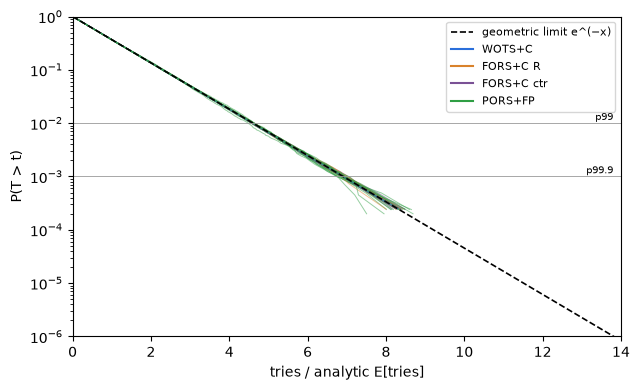

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4))
x = np.linspace(0, 14, 300)
for cid, r in s.iterrows():
    v = np.sort(C.tries(cid) / r.expected_tries)
    ccdf = 1 - np.arange(1, len(v) + 1) / len(v)
    k = slice(None, None, max(1, len(v) // 4000))
    ax.semilogy(v[k], ccdf[k], lw=0.7, alpha=0.5, color={'wots': '#2a6fdb', 'R': '#d9822b', 'ctr': '#7a5195', 'pors': '#2f9e44'}[r.kind])
ax.semilogy(x, np.exp(-x), 'k--', lw=1.2, label='geometric limit e^(−x)')
for q in (0.99, 0.999):
    ax.axhline(1 - q, color='0.6', lw=0.6); ax.text(13.8, (1 - q) * 1.15, f'p{100*q:g}', ha='right', fontsize=7)
for k, c in {'WOTS+C': '#2a6fdb', 'FORS+C R': '#d9822b', 'FORS+C ctr': '#7a5195', 'PORS+FP': '#2f9e44'}.items():
    ax.plot([], [], color=c, label=k)
ax.set_xlim(0, 14); ax.set_ylim(1e-6, 1); ax.set_xlabel('tries / analytic E[tries]'); ax.set_ylabel('P(T > t)')
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(OUT / 'ccdf_normalized.png', dpi=160); fig.savefig(OUT / 'ccdf_normalized.svg')

## Per-signature grind work

Resampled from the measured per-instance tries: n = 2·10⁵ synthetic signatures per point and layout.
Compressions use the counted per-attempt cost (WOTS+C 1, R-grind 6, ctr-grind 3, PORS+FP 7).
`model_worst_2^-30` is the Kudinov–Nick analytic worst case (sum of per-component bounds at q = 2⁻³⁰),
re-priced with the same per-attempt costs. Plain-FORS points (`wots_c+fors`) only grind WOTS+C.

In [4]:
from runner.configs import COMPRESSIONS
sl = C.shortlist()
rows, samples = [], {}
for pid, fcid, kind in C.point_layouts():
    pt = sl.loc[pid]
    w, f = C.signature_grind_samples(pid, fcid)
    comp = w + f * (COMPRESSIONS[kind] if kind else 0)
    samples[(pid, kind)] = (w, f, comp)
    worst = pt.model_wots_c_worst_2m30_all_layers + (pt.model_fts_worst_2m30 * COMPRESSIONS[kind] if kind else 0)
    q = np.quantile(comp, Q)
    rows.append({'param_id': pid, 'profile': pt.profile, 'layout': kind or '-', 'sig_limit': int(pt.sig_limit_log2),
                 'sig_bytes': int(pt.sig_bytes), 'grind_mean': comp.mean(), 'grind_p50': q[0], 'grind_p99': q[2],
                 'grind_p999': q[3], 'p999_over_mean': q[3] / comp.mean(), 'model_worst_2^-30': worst,
                 'worst_over_mean': worst / comp.mean(), 'wots_share_mean': w.mean() / comp.mean()})
sg = pd.DataFrame(rows).set_index(['param_id', 'layout'])
sg.to_csv(OUT / 'signature_grind.csv'); C.to_markdown(sg.round(3), OUT / 'signature_grind.md')
sg[['profile', 'sig_bytes', 'grind_mean', 'grind_p99', 'grind_p999', 'p999_over_mean', 'worst_over_mean', 'wots_share_mean']]

profile  \
param_id                                layout                        
L20-WC-h20d2-k10a15-w256S2040z0         -           blockstream_ref   
L20-WC-h24d2-k8a16-w16S240z0            -           blockstream_ref   
L20-WC-h24d2-k8a16-w256S2040z0          -           blockstream_ref   
L20-WCFC-h20d2-k10a15-w256S2040z0       R           blockstream_ref   
                                        ctr         blockstream_ref   
L20-WCFC-h24d2-k8a16-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L20-WCPFP-h20d2-k10a15-w256S2040z0-m114 pors        blockstream_ref   
L20-WCPFP-h24d2-k7a18-w256S1912z1-m94   pors    gpu_signer_moderate   
L20-WCPFP-h24d2-k8a16-w16S240z0-m97     pors        blockstream_ref   
L20-WCPFP-h27d3-k10a12-w256S2040z0-m93  pors         hw_wallet_safe   
L20-WCPFP-h32d2-k11a10-w256S1912z1-m68  pors         gpu_signer_max   
L30-WC-h32d4-k10a14-w256S2040z0         -           blockstream_ref   
L30-WC-h32d4-k10a14-w256S2840z0         -           blockstream_ref   
L30-WC-h33d3-k9a15-w16S240z0            -           blockstream_ref   
L30-WC-h33d3-k9a15-w16S304z0            -           blockstream_ref   
L30-WC-h33d3-k9a15-w256S2040z0          -           blockstream_ref   
L30-WC-h36d3-k9a14-w16S240z0            -           blockstream_ref   
L30-WCFC-h32d2-k7a19-w256S1912z1        R             fors_c_stress   
                                        ctr           fors_c_stress   
L30-WCFC-h32d4-k10a14-w256S2040z0       R           blockstream_ref   
                                        ctr         blockstream_ref   
L30-WCFC-h33d3-k9a15-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L30-WCFC-h33d3-k9a15-w256S2040z0        R           blockstream_ref   
                                        ctr         blockstream_ref   
L30-WCFC-h36d3-k9a14-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L30-WCPFP-h32d2-k7a19-w256S1912z1-m96   pors         gpu_signer_max   
L30-WCPFP-h32d2-k7a19-w256S2512z1-m96   pors          wots_c_stress   
L30-WCPFP-h32d4-k10a14-w256S2040z0-m106 pors        blockstream_ref   
L30-WCPFP-h32d4-k9a15-w256S2040z0-m109  pors         hw_wallet_safe   
L30-WCPFP-h33d3-k8a16-w256S1912z1-m94   pors    gpu_signer_moderate   
L30-WCPFP-h33d3-k9a15-w16S240z0-m103    pors        blockstream_ref   
L30-WCPFP-h36d3-k9a14-w16S240z0-m93     pors        blockstream_ref   
L40-WC-h40d5-k11a14-w256S2040z0         -           blockstream_ref   
L40-WC-h40d5-k11a14-w256S2840z0         -           blockstream_ref   
L40-WC-h44d4-k8a16-w16S240z0            -           blockstream_ref   
L40-WC-h44d4-k8a16-w16S304z0            -           blockstream_ref   
L40-WC-h44d4-k8a16-w256S2040z0          -           blockstream_ref   
L40-WCFC-h40d5-k11a14-w256S2040z0       R           blockstream_ref   
                                        ctr         blockstream_ref   
L40-WCFC-h44d4-k8a16-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L40-WCPFP-h40d5-k11a14-w256S2040z0-m118 pors        blockstream_ref   
L40-WCPFP-h44d4-k8a16-w16S240z0-m97     pors        blockstream_ref   
L40-WCPFP-h48d3-k9a13-w256S1912z1-m77   pors         gpu_signer_max   
L40-WCPFP-h48d4-k9a13-w256S1912z1-m82   pors    gpu_signer_moderate   
L40-WCPFP-h48d6-k9a13-w256S2440z0-m91   pors         hw_wallet_safe   

                                                sig_bytes    grind_mean  \
param_id                                layout                            
L20-WC-h20d2-k10a15-w256S2040z0         -            3416  1.494430e+03   
L20-WC-h24d2-k8a16-w16S240z0            -            3608  1.311233e+02   
L20-WC-h24d2-k8a16-w256S2040z0          -            3096  1.494430e+03   
L20-WCFC-h20d2-k10a15-w256S2040z0       R            3160  1.98

`p999_over_mean` is below 6.9 for points where the grind is a *sum* of several comparable geometric
components (d WOTS+C layers + FTS): sums concentrate. It approaches 6.9 when one component dominates.

## Grinding time per signer class (p50 / p99 / p99.9)

In [5]:
lad = C.ladder()
m = C.measured_rates()
print(lad)
tt = {}
for (pid, kind), (w, f, comp) in samples.items():
    row = {}
    for cls, r in lad.iterrows():
        for q, lbl in ((0.5, 'p50'), (0.99, 'p99'), (0.999, 'p99.9')):
            row[(r.label, lbl)] = np.quantile(comp, q) / r.comp_per_s
    # GPU as actually measured: per-kernel attempt rates, not the raw E0 rate
    sec = w / m['gpu_effective']['wots'] + (f * COMPRESSIONS[kind] / m['gpu_effective'][kind] if kind else 0)
    for q, lbl in ((0.5, 'p50'), (0.99, 'p99'), (0.999, 'p99.9')):
        row[('RTX 4050 measured kernels', lbl)] = np.quantile(sec, q)
    tt[(pid, kind or '-')] = row
tt = pd.DataFrame(tt).T
tt.columns = pd.MultiIndex.from_tuples(tt.columns)
tt.index.names = ['param_id', 'layout']
tt.to_csv(OUT / 'grind_seconds_by_class.csv')
pretty = tt.xs('p99.9', axis=1, level=1).map(C.fmt_seconds)
pretty.insert(0, 'sig_bytes', sl.loc[pretty.index.get_level_values(0), 'sig_bytes'].to_numpy())
pretty.insert(1, 'profile', sl.loc[pretty.index.get_level_values(0), 'profile'].to_numpy())
C.to_markdown(pretty, OUT / 'grind_p999_seconds_by_class.md')
pretty

                                            label    comp_per_s      kind
class_id                                                                 
class0a   HW wallet MCU, software SHA (Cortex-M4)  4.000000e+04   derived
class0b            HW wallet MCU + SHA peripheral  1.200000e+05   derived
class1b               Raspberry Pi 5 (ARMv8 SHA2)  7.400000e+07   derived
class2               i5-13420H SHA-NI, 12 threads  2.328321e+08  measured
class3                     RTX 4050 Laptop @ 45 W  2.151389e+09  measured
class4                         8x RTX 4090 server  1.720000e+11     cited


sig_bytes  \
param_id                                layout              
L20-WC-h20d2-k10a15-w256S2040z0         -            3416   
L20-WC-h24d2-k8a16-w16S240z0            -            3608   
L20-WC-h24d2-k8a16-w256S2040z0          -            3096   
L20-WCFC-h20d2-k10a15-w256S2040z0       R            3160   
                                        ctr          3160   
L20-WCFC-h24d2-k8a16-w16S240z0          R            3336   
                                        ctr          3336   
L20-WCPFP-h20d2-k10a15-w256S2040z0-m114 pors         2840   
L20-WCPFP-h24d2-k7a18-w256S1912z1-m94   pors         2504   
L20-WCPFP-h24d2-k8a16-w16S240z0-m97     pors         3112   
L20-WCPFP-h27d3-k10a12-w256S2040z0-m93  pors         2876   
L20-WCPFP-h32d2-k11a10-w256S1912z1-m68  pors         2280   
L30-WC-h32d4-k10a14-w256S2040z0         -            3968   
L30-WC-h32d4-k10a14-w256S2840z0         -            3968   
L30-WC-h33d3-k9a15-w16S240z0            -            4396   
L30-WC-h33d3-k9a15-w16S304z0            -            4396   
L30-WC-h33d3-k9a15-w256S2040z0          -            3628   
L30-WC-h36d3-k9a14-w16S240z0            -            4300   
L30-WCFC-h32d2-k7a19-w256S1912z1        R            2936   
                                        ctr          2936   
L30-WCFC-h32d4-k10a14-w256S2040z0       R            3728   
                                        ctr          3728   
L30-WCFC-h33d3-k9a15-w16S240z0          R            4140   
                                        ctr          4140   
L30-WCFC-h33d3-k9a15-w256S2040z0        R            3372   
                                        ctr          3372   
L30-WCFC-h36d3-k9a14-w16S240z0          R            4060   
                                        ctr          4060   
L30-WCPFP-h32d2-k7a19-w256S1912z1-m96   pors         2664   
L30-WCPFP-h32d2-k7a19-w256S2512z1-m96   pors         2664   
L30-WCPFP-h32d4-k10a14-w256S2040z0-m106 pors         3424   
L30-WCPFP-h32d4-k9a15-w256S2040z0-m109  pors         3456   
L30-WCPFP-h33d3-k8a16-w256S1912z1-m94   pors         2908   
L30-WCPFP-h33d3-k9a15-w16S240z0-m103    pors         3884   
L30-WCPFP-h36d3-k9a14-w16S240z0-m93     pors         3772   
L40-WC-h40d5-k11a14-w256S2040z0         -            4596   
L40-WC-h40d5-k11a14-w256S2840z0         -            4596   
L40-WC-h44d4-k8a16-w16S240z0            -            4960   
L40-WC-h44d4-k8a16-w16S304z0            -            4960   
L40-WC-h44d4-k8a16-w256S2040z0          -            3936   
L40-WCFC-h40d5-k11a14-w256S2040z0       R            4356   
                                        ctr          4356   
L40-WCFC-h44d4-k8a16-w16S240z0          R            4688   
                                        ctr          4688   
L40-WCPFP-h40d5-k11a14-w256S2040z0-m118 pors         4020   
L40-WCPFP-h44d4-k8a16-w16S240z0-m97     pors         4464   
L40-WCPFP-h48d3-k9a13-w256S1912z1-m77   pors         2892   
L40-WCPFP-h48d4-k9a13-w256S1912z1-m82   pors         3216   
L40-WCPFP-h48d6-k9a13-w256S2440z0-m91   pors         3944   

                                                            profile  \
param_id                                layout                        
L20-WC-h20d2-k10a15-w256S2040z0         -           blockstream_ref   
L20-WC-h24d2-k8a16-w16S240z0            -           blockstream_ref   
L20-WC-h24d2-k8a16-w256S2040z0          -           blockstream_ref   
L20-WCFC-h20d2-k10a15-w256S2040z0       R           blockstream_ref   
                                        ctr         blockstream_ref   
L20-WCFC-h24d2-k8a16-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L20-WCPFP-h20d2-k10a15-w256S2040z0-m114 pors        blockstream_ref   
L20-WCPFP-h24d2-k7a18-w256S1912z1-m94   pors    gpu_signer_moderate   
L20-WCPFP-h24d2-k8a16-w16S240z0-m97     pors        blockstream_ref   
L20-WCPFP-h27d3-k10a12-w256S2040z0-m93  pors         hw_wallet_safe   
L20-WCPFP-h32

Classes 0a/0b/1b/4 are *cited* rates (Agent D, `kb/hardware.yaml`), classes 2/3 are measured on the test
laptop (E5 sustained 12-thread, E0 sustained). Single-signature GPU latency equals batch throughput only
when one grind fills the GPU (E[tries] ≳ 10⁵); small grinds are bounded below by kernel-launch overhead (tens of µs, not measured here).

## E5 cross-check: CPU per-instance seconds vs. tries ÷ rate

In [6]:
rows = []
for g in C.e5()['grind']:
    cid = g['config_id']
    d = pd.read_parquet(C.run_dir() / 'e5' / f'{cid}.parquet')
    tr = d.counter.to_numpy(np.float64) + 1
    rate1 = (tr.sum() / d.seconds.sum())  # attempts per second per thread
    rows.append({'config_id': cid, 'n': len(d), 'attempts_per_s_per_thread': rate1,
                 'attempts_per_s_12t': g['attempts_per_s'], 'sec_p99': g['sec_p99'], 'sec_p999': g['sec_p999'],
                 'pred_p99': np.quantile(tr, 0.99) / rate1, 'pred_p999': np.quantile(tr, 0.999) / rate1,
                 'gpu_over_cpu_attempts': s.loc[cid, 'attempts_per_s'] / g['attempts_per_s']})
e5t = pd.DataFrame(rows).set_index('config_id')
C.to_markdown(e5t, OUT / 'e5_crosscheck.md'); e5t

,n,attempts_per_s_per_thread,attempts_per_s_12t,sec_p99,sec_p999,pred_p99,pred_p999,gpu_over_cpu_attempts
config_id,,,,,,,,
wots-w16-S240-z0,10000,1.124000e+07,1.007183e+08,0.000024,0.000085,0.000027,0.000038,2.477290
wots-w256-S2040-z0,10000,1.702057e+07,1.969555e+08,0.000203,0.000334,0.000201,0.000303,4.829660
wots-w16-S304-z0,10000,1.276419e+07,1.515428e+08,0.000492,0.000817,0.000477,0.000688,7.806428
wots-w256-S2440-z0,10000,1.691380e+07,1.993366e+08,0.000505,0.000789,0.000492,0.000755,6.756502
wots-w256-S2840-z0,10000,1.633448e+07,1.950064e+08,0.008487,0.014227,0.008285,0.012647,8.073584
wots-w256-S1912-z1,10000,2.062765e+07,2.466395e+08,0.042146,0.062248,0.041077,0.061686,6.644762
wots-w256-S2512-z1,10000,1.803087e+07,2.158879e+08,0.445632,0.732414,0.426987,0.649190,8.051619


Per-instance CPU times track tries ÷ per-thread rate, so the tries tables convert to time linearly.
For the small WOTS+C grinds the 12-thread attempt rate is below the raw SHA-NI rate (per-instance setup
dominates); for E[tries] ≳ 10³ it approaches it.